In [8]:
import time
inicio = time.time()
import random
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'Palatino Linotype'
rcParams['font.family'] = 'Palatino Linotype'
cm = 1/2.54
rcParams["figure.figsize"] = (15*cm, 8*cm)
rcParams["figure.dpi"] = 100
rcParams["font.size"] = 8
# prop_cycle = plt.rcParams['axes.prop_cycle']
# colors = prop_cycle.by_key()['color']
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras

In [9]:
def reading(input='unica_entrada.xlsx'):
    table = pd.read_excel(input)
    Salimax = table['Sali'].max()
    Salimax_ = table['Sali'].max()
    table['Sali'] = table['Sali'] / Salimax
    table['Sali_'] = table['Sali_'] / Salimax_
    X = table.drop(table.columns[302:], axis=1)
    Y = table.drop(table.columns[:302], axis=1)
    return [X, Y]

In [10]:
def training(X, Y, epochs=200):
    tf.random.set_seed(42)
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.33)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(Y.shape[1], input_shape=(X.shape[1],), activation='relu'),
        tf.keras.layers.Dense(Y.shape[1], activation='relu'),
        tf.keras.layers.Dense(Y.shape[1], activation='relu'),
        tf.keras.layers.Dense(Y.shape[1], activation='sigmoid')
    ])

    model.compile(loss=tf.keras.losses.mae,
                  optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
                  metrics=["mse", "mae"])

    history = model.fit(X_train, Y_train, verbose=0, epochs=epochs)
    print("treinada...")

    fig_hist, ax_hist = plt.subplots()
    ax_hist.loglog(history.history["mse"], label="mse", ls='-.')
    ax_hist.loglog(history.history["mae"], label="mae")
    ax_hist.set_xlabel("Época #")
    ax_hist.set_ylabel(r"Erro")
    ax_hist.grid(alpha=0.5, lw=0.1)
    ax_hist.legend()
    fig_hist.savefig("fig_hist.png", bbox_inches='tight', dpi=600)

    return [X_train, X_test, Y_train, Y_test, model, history]

In [11]:
def prediction(X_train, X_test, Y_train, Y_test, model):
    Y_pred_train = model.predict(X_train)
    error_train = (Y_pred_train - Y_train).values
    mse_error_train = np.zeros(error_train.shape[0])
    for ii in range(error_train.shape[0]):
        mse_error_train[ii] = np.sqrt(np.dot(error_train[ii, :], error_train[ii, :])/error_train.shape[1])
    Y_pred_test = model.predict(X_test)
    error_test = (Y_pred_test - Y_test).values
    mse_error_test = np.zeros(error_test.shape[0])
    for ii in range(error_test.shape[0]):
        mse_error_test[ii] = np.sqrt(np.dot(error_test[ii, :], error_test[ii, :])/error_test.shape[1])

    fig_error, ax_error = plt.subplots()
    ax_error.plot(np.arange(error_train.shape[0]), mse_error_train, label='train', ls='-.')
    ax_error.plot(error_train.shape[0]+np.arange(0, error_test.shape[0], 1),  mse_error_test, label='test', ls=':')
    ax_error.set_xlabel("Amostra #")
    ax_error.set_ylabel(r"Erro Médio Quadrático")
    ax_error.grid(alpha=0.5, lw=0.1)
    ax_error.legend()
    fig_error.savefig("fig_error.png", bbox_inches='tight', dpi=600)

    return [error_test, mse_error_test]

In [12]:
def graphic_comparison(X_test):
    Y_pred = model.predict(X_test.values)
    nr_amostras = X_test.values.shape[0]
    plt.rcParams.update({'font.size': 4})
    fig, ax = plt.subplots(nrows=int(nr_amostras/3), ncols=3, figsize = (18*cm, 30*cm), sharex=True,sharey=True)
    fig.dpi = 300
    kk = 0
    erro_sw = np.zeros((nr_amostras, 100))
    erro_o  = np.zeros((nr_amostras, 100))
    erro_w  = np.zeros((nr_amostras, 100))
    swswsw  = np.zeros((nr_amostras, 100))
    for ii in range(int(nr_amostras/3)):
        for jj in range(3):
            # Predictions
            xxx_pred = Y_pred[kk,   0:100]
            ooo_pred = Y_pred[kk, 100:200]
            www_pred = Y_pred[kk, 200:300]
            ax[ii, jj].plot(xxx_pred, ooo_pred, label=str(kk), color='blue', lw=0.5)
            ax[ii, jj].plot(xxx_pred, www_pred,                color='black', lw=0.5)
            # Original data
            xxx_data = Y_test.values[kk,   0:100]
            ooo_data = Y_test.values[kk, 100:200]
            www_data = Y_test.values[kk, 200:300]
            salin_curva_dada = X_test.values[kk, 301]
            salin_curva_desejada = X_test.values[kk, 0]
            ax[ii, jj].plot(xxx_data, ooo_data, label=str(kk), color='gray', alpha=0.3, lw=2)
            ax[ii, jj].plot(xxx_data, www_data,                color='gray', alpha=0.5, lw=2)
            ax[ii, jj].grid(alpha=0.5, lw=0.1)
            # Deviation 
            swswsw[kk]  = xxx_data
            erro_sw[kk] = abs(xxx_pred - xxx_data) / xxx_data
            erro_o[kk]  = abs(ooo_pred - ooo_data) / ooo_data
            erro_w[kk]  = abs(www_pred - www_data) / www_data
            erro_sw[np.isnan(erro_sw)] = 0
            erro_o[np.isnan(erro_o)]   = 0
            erro_w[np.isnan(erro_w)]   = 0
            kk = kk + 1

    fig.savefig("graphic_comparison.png", bbox_inches='tight', dpi=600)
    return [Y_pred, swswsw, erro_o, erro_w, erro_sw]

In [13]:
def graphics_erros(swswsw, erro_o, erro_w, erro_sw):
    nr_amostras = swswsw.shape[0]
    plt.rcParams.update({'font.size': 4})
    fig, ax = plt.subplots(nrows=int(nr_amostras/3), ncols=3, figsize = (18*cm, 30*cm), sharex=True,sharey=True)
    fig.dpi = 300
    kk = 0
    for ii in range(int(nr_amostras/3)):
        for jj in range(3):
            ax[ii, jj].plot(swswsw[kk], erro_sw[kk],               color='red', lw=0.5)
            ax[ii, jj].plot(swswsw[kk], erro_w[kk], label=str(kk), color='blue', lw=0.5)
            ax[ii, jj].plot(swswsw[kk], erro_o[kk],                color='black', lw=0.5)
            ax[ii, jj].set_yscale('symlog')
            ax[ii, jj].grid(alpha=0.5, lw=0.1)
            kk = kk + 1

    fig.savefig("graphics_erros.png", bbox_inches='tight', dpi=600)

treinada...


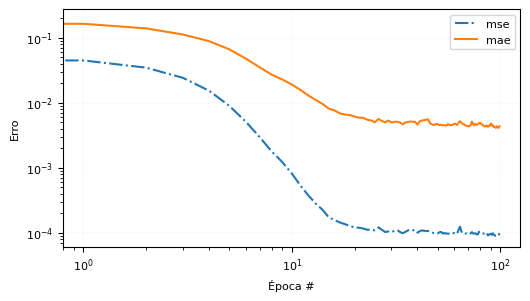

In [14]:
X, Y = reading(input='unica_entrada.xlsx')
X_train, X_test, Y_train, Y_test, model, history = training(X, Y, epochs=100)
# model.save('modelo')
# reconstructed_model = keras.models.load_model("my_h5_model.h5")


2/2 [==============================] - 0s 8ms/step


<ipython-input-12-854f41d9826c>:32: RuntimeWarning: divide by zero encountered in true_divide
  erro_o[kk]  = abs(ooo_pred - ooo_data) / ooo_data
<ipython-input-12-854f41d9826c>:32: RuntimeWarning: divide by zero encountered in true_divide
  erro_o[kk]  = abs(ooo_pred - ooo_data) / ooo_data
<ipython-input-12-854f41d9826c>:33: RuntimeWarning: divide by zero encountered in true_divide
  erro_w[kk]  = abs(www_pred - www_data) / www_data
<ipython-input-12-854f41d9826c>:32: RuntimeWarning: divide by zero encountered in true_divide
  erro_o[kk]  = abs(ooo_pred - ooo_data) / ooo_data
<ipython-input-12-854f41d9826c>:32: RuntimeWarning: divide by zero encountered in true_divide
  erro_o[kk]  = abs(ooo_pred - ooo_data) / ooo_data
<ipython-input-12-854f41d9826c>:33: RuntimeWarning: divide by zero encountered in true_divide
  erro_w[kk]  = abs(www_pred - www_data) / www_data
<ipython-input-12-854f41d9826c>:32: RuntimeWarning: divide by zero encountered in true_divide
  erro_o[kk]  = abs(ooo_pred -

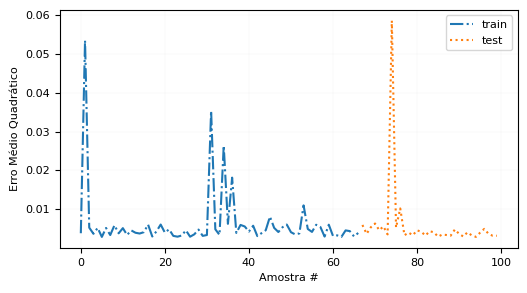

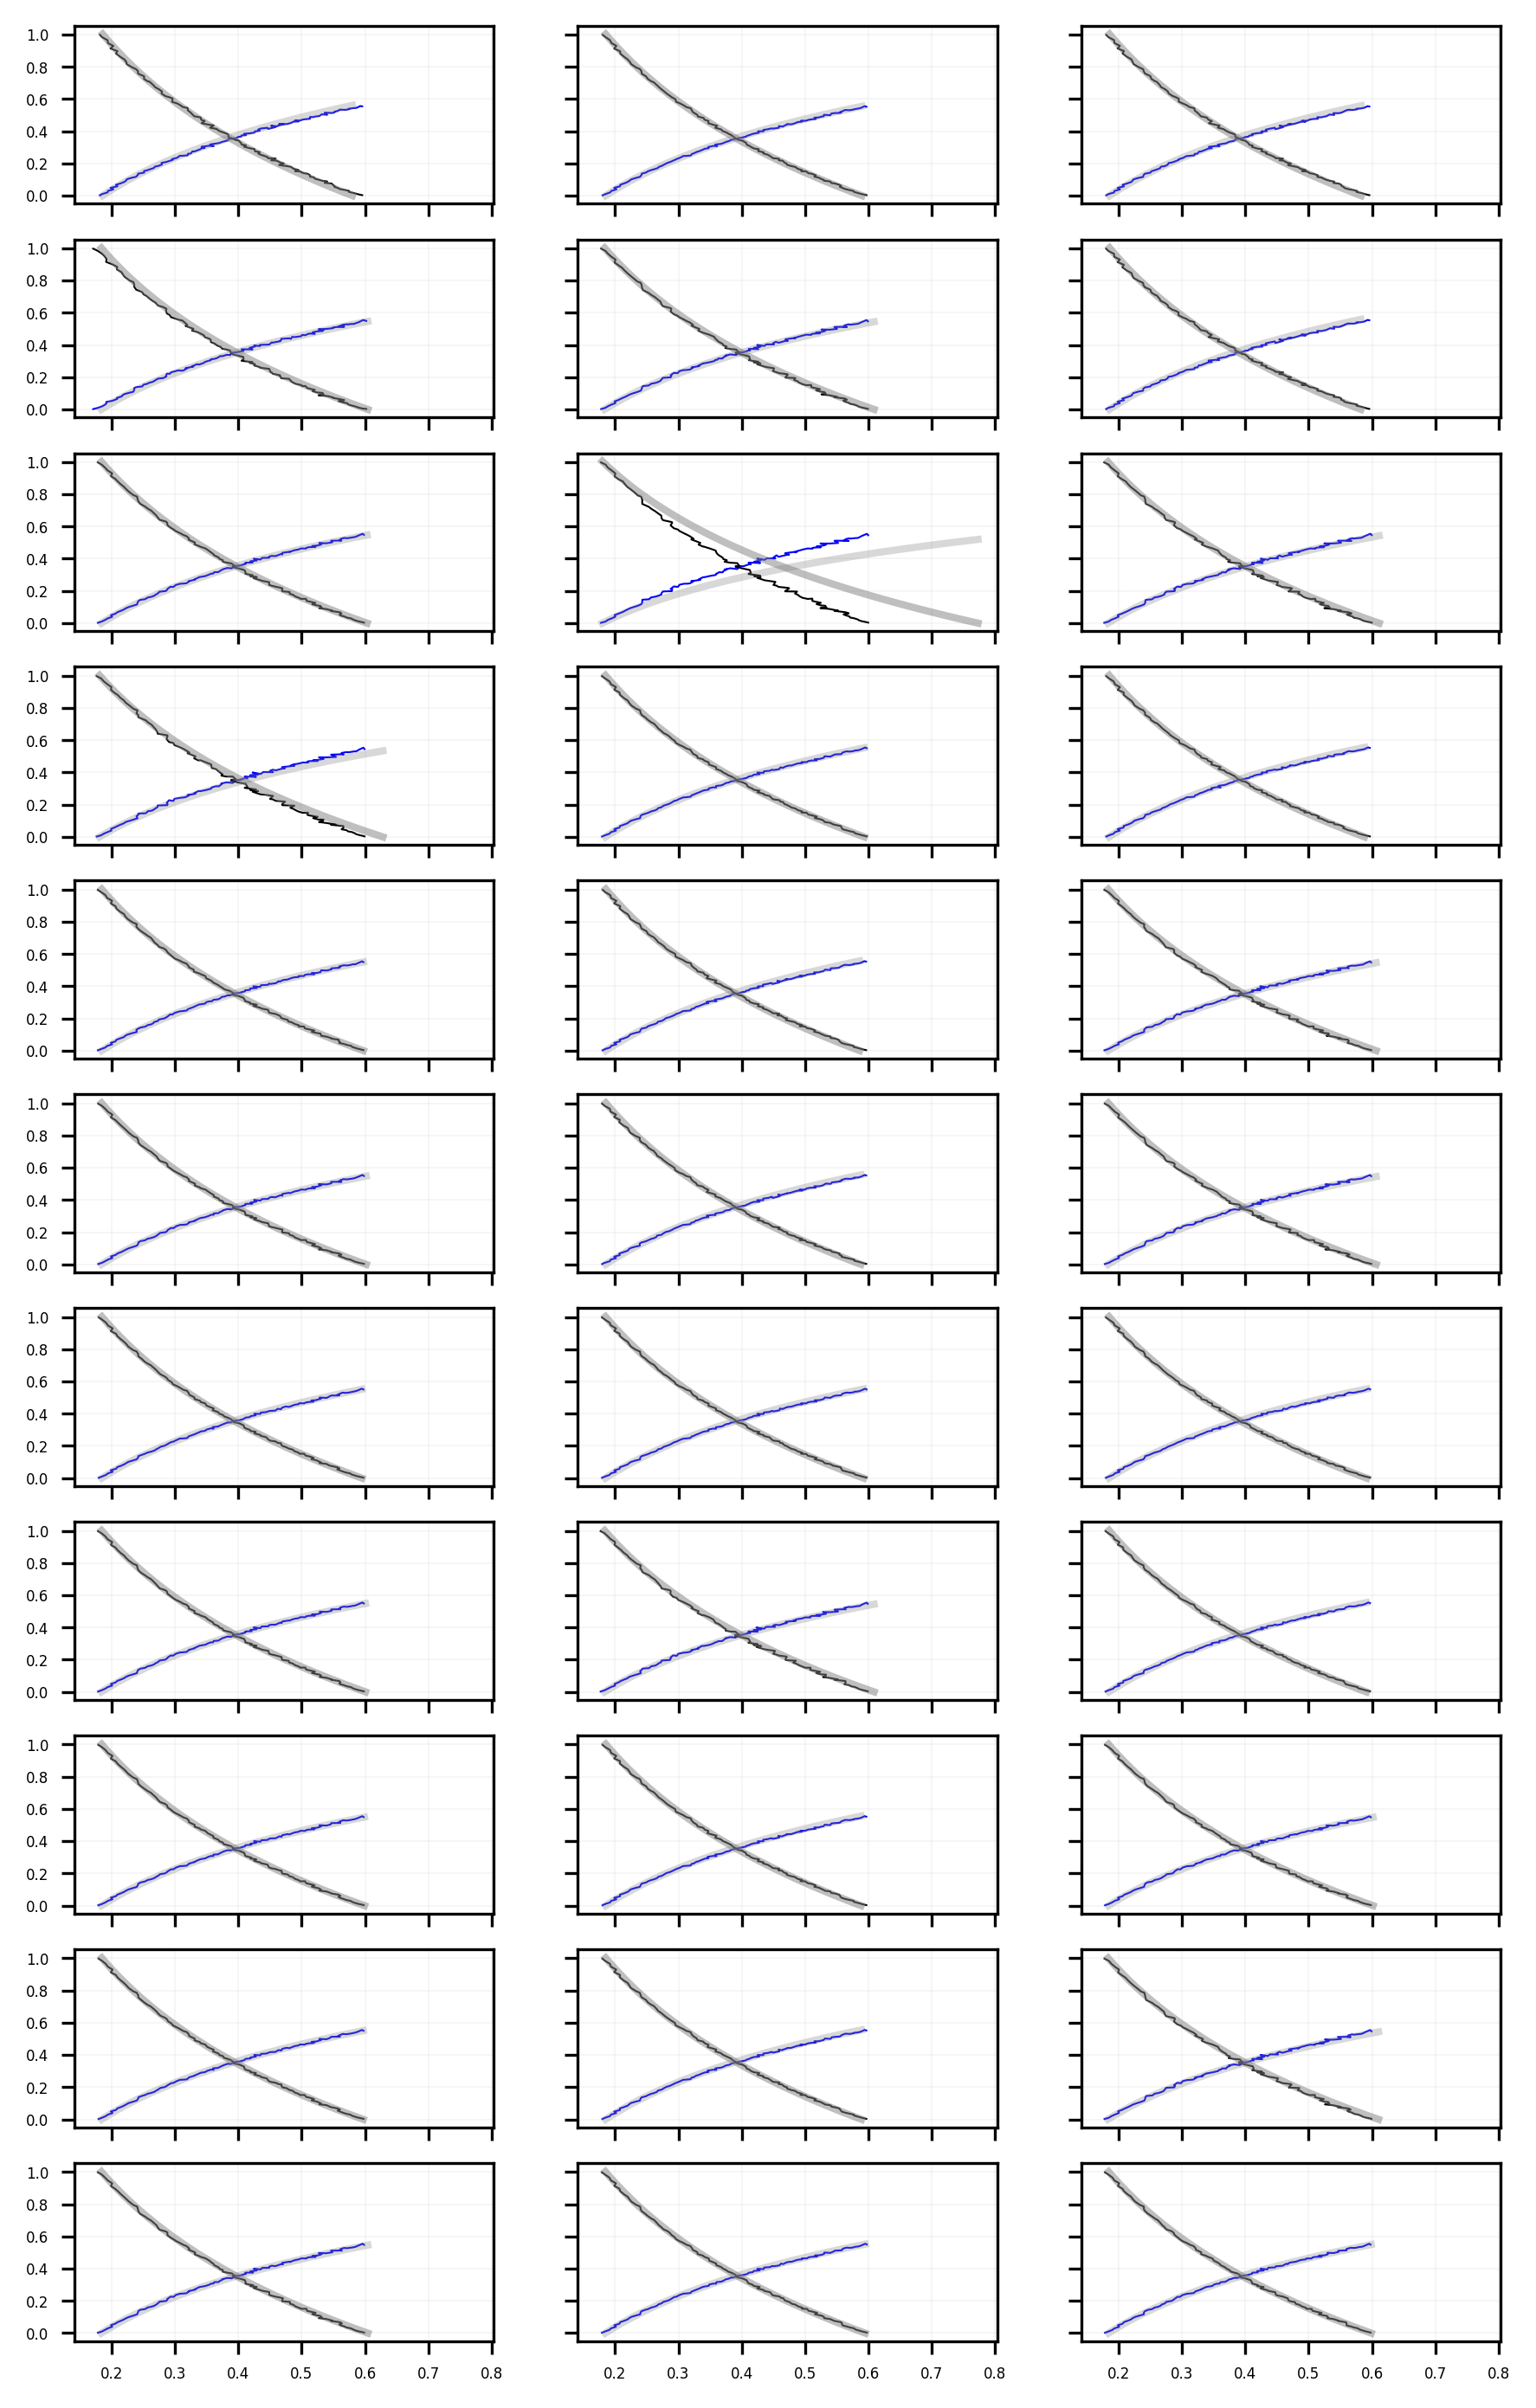

In [15]:
error_test, mse_error_test = prediction(X_train, X_test, Y_train, Y_test, model)
Y_pred, swswsw, erro_o, erro_w, erro_sw = graphic_comparison(X_test)

tempo_de_execucao =  39.33101034164429


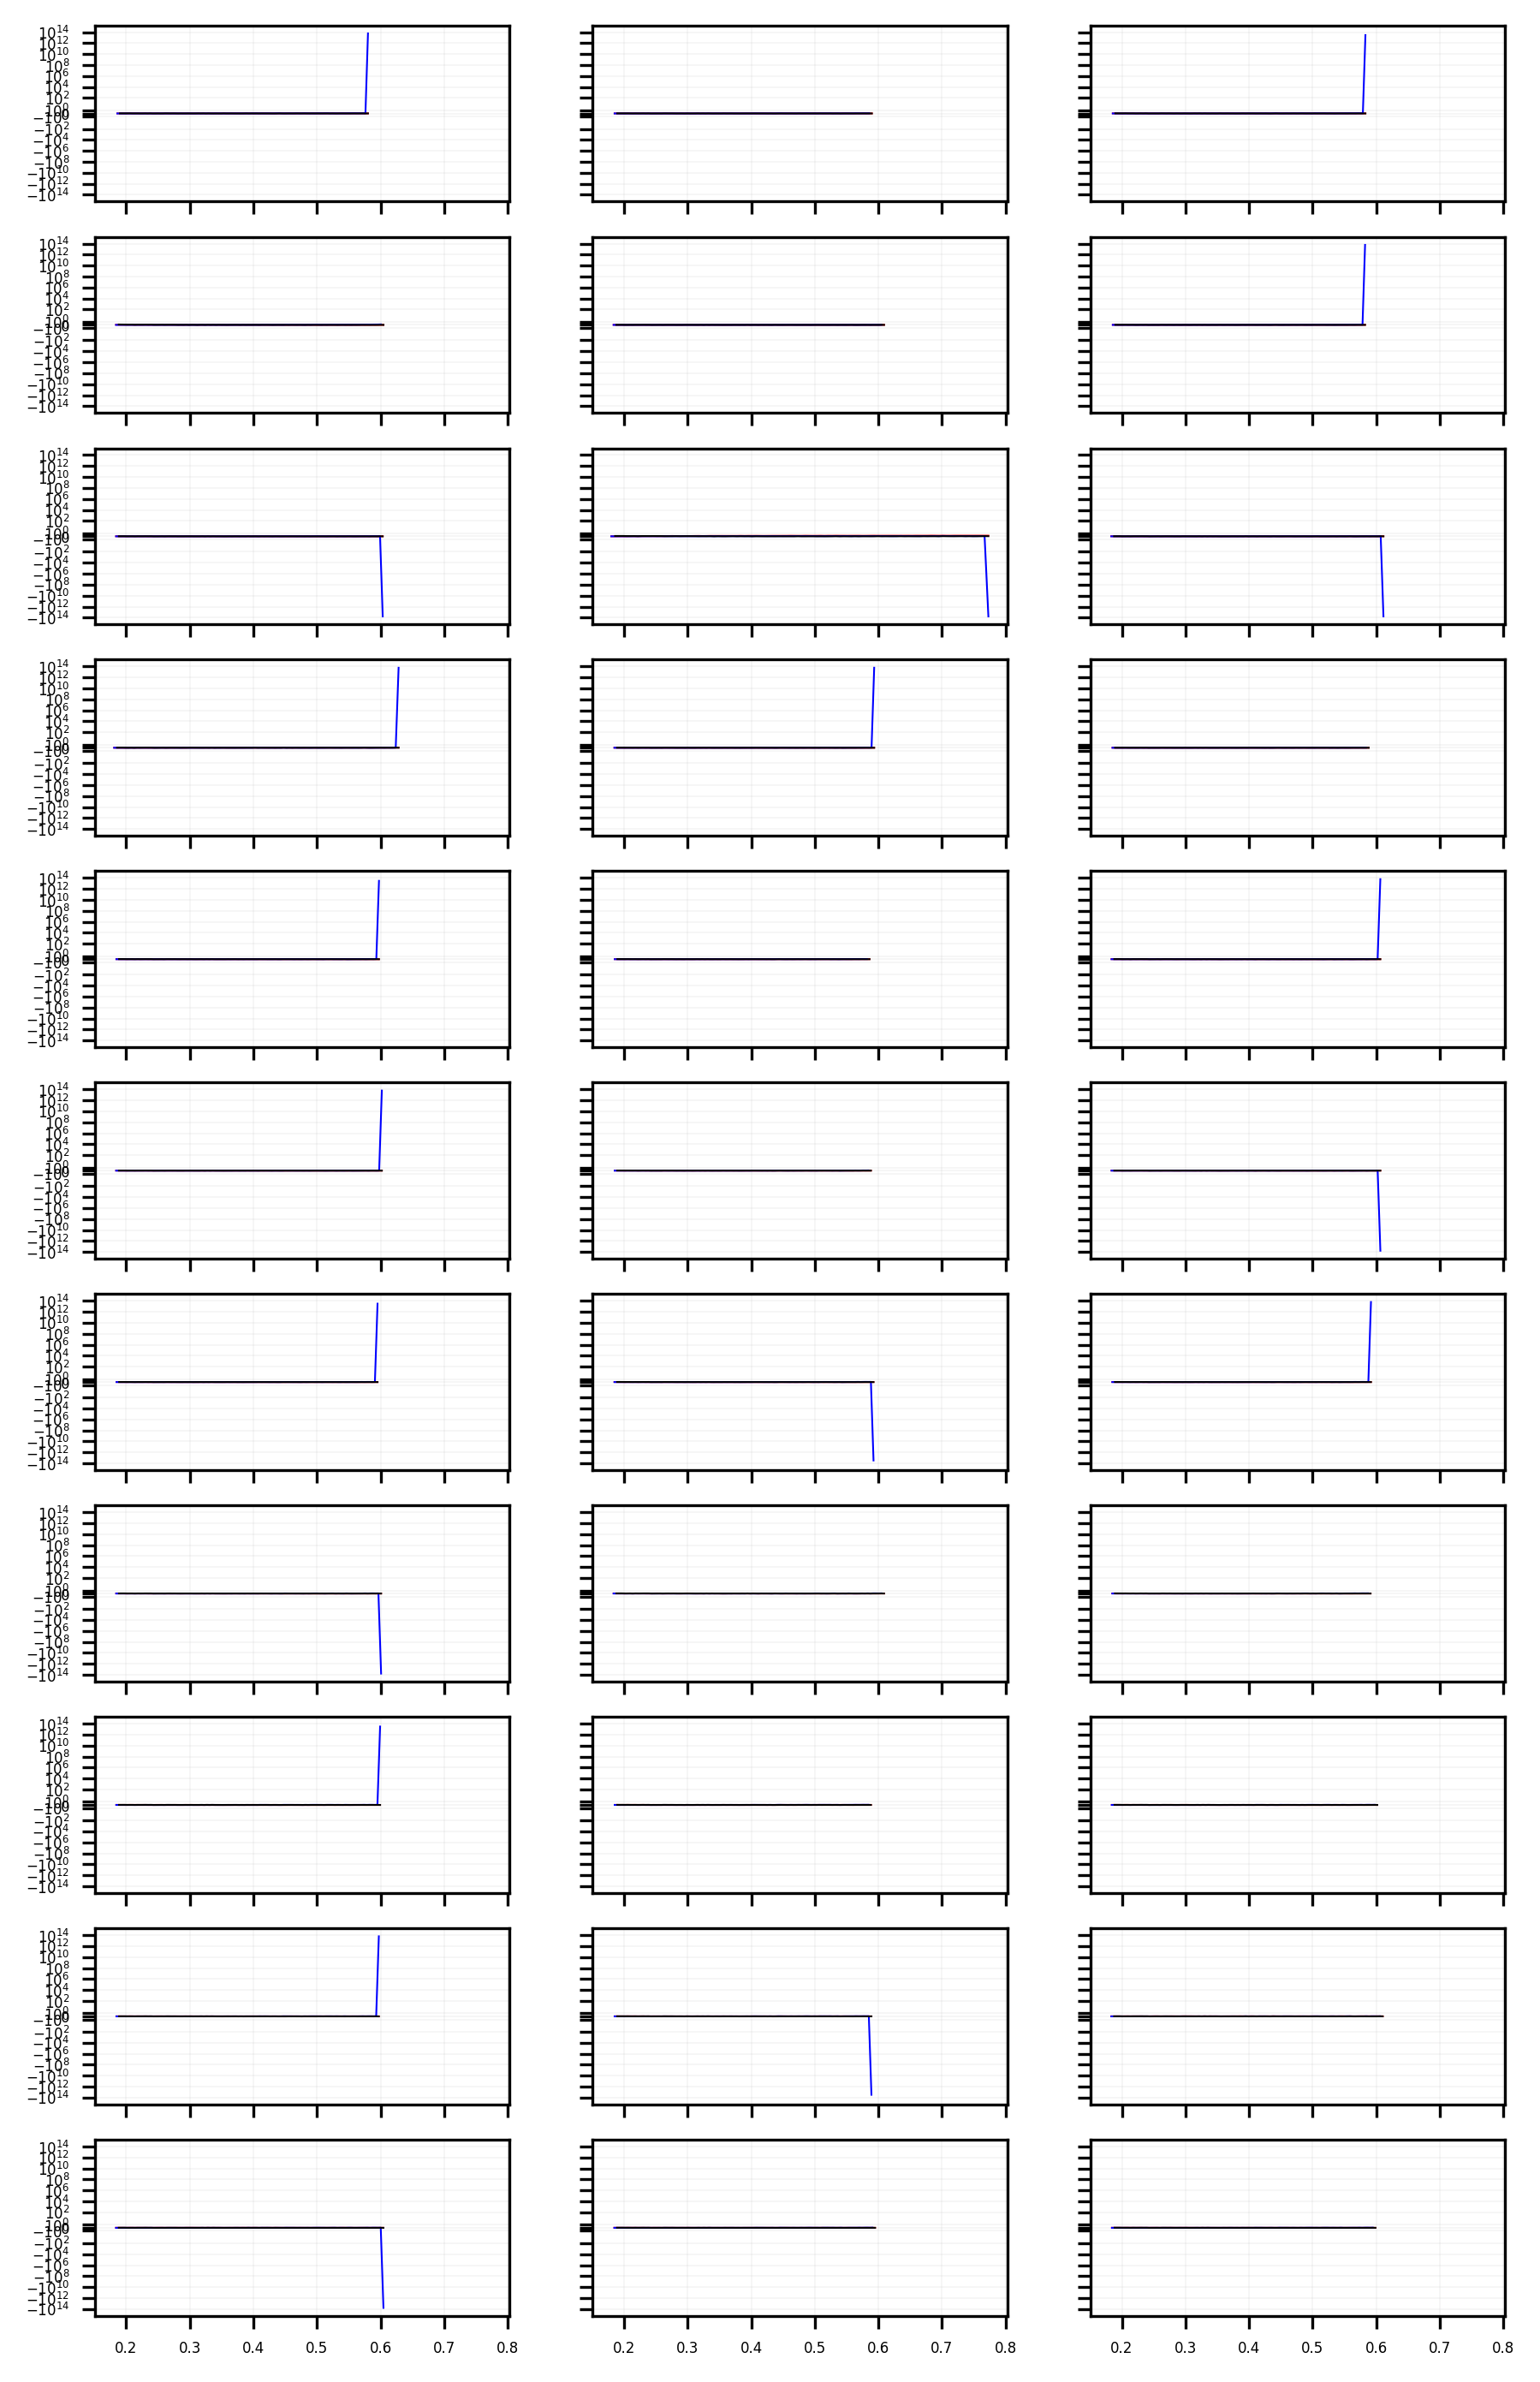

In [16]:
graphics_erros(swswsw, erro_o, erro_w, erro_sw)
fim = time.time()
tempo_de_execucao = fim - inicio
print("tempo_de_execucao = ", tempo_de_execucao)

In [17]:
model.save("my_h5_model.h5")

In [18]:
from google.colab import files
files.download('my_h5_model.h5') 
files.download('/content/fig_error.png') 
files.download('/content/fig_hist.png') 
files.download('/content/graphic_comparison.png') 
files.download('/content/graphics_erros.png') 
files.download('/content/unica_entrada.xlsx') 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>